# Phase 2 — Data-Pipeline Failure Prediction (DPFP)
### Leakage-free next-day forecasting of pipeline failures from data-centric signals

**Research question:** *Which data-pipeline failures are forecastable one day ahead from the pipeline's own data-quality telemetry, how early, and how much do same-run leakage and infrastructure-only signals mislead?*

**Key findings (headline).**
1. **Not all failures are equal (N1).** A per-failure-type map shows **data-quality** failures are forecastable one day ahead (lift > 1 with a confidence interval above 1), while transient infrastructure failures are near-random — so the right question is *which* failures are predictable, not *whether* failures are.
2. **Data-centric signals beat infrastructure signals (N2).** A model using only data-quality telemetry (drift, freshness, stagnation, invalid values) out-predicts an infrastructure-only model on the same test window.
3. **Same-run leakage inflates results to near-perfect (N5).** Scoring with same-run features gives PR-AUC ≈ 1.0; the honest next-day model is far lower — quantifying a trap much of the prior literature falls into.
4. **It is honestly hard, and that is the point.** With a realistic failure definition (genuine high pollution is a *warning*, not a failure), the leakage-free task is modest but real and beats every one-line rule baseline.

| Section | What it does | Objective / Novelty |
|---|---|---|
| 1 | Load + audit both city logs | Obj 1 |
| 2 | Target (`next-day failure`) + causal features in 3 groups | Obj 1, 2 |
| 3 | Chronological train / validation / test split (≥30 test failures check) | Obj 2 |
| 4 | Model + class-imbalance ablation (None / Weights / SMOTE / Both) | Methodology |
| 5 | Probability calibration (Platt, on un-resampled validation data) | Methodology |
| 6 | Baselines + **infra-vs-data ablation** with bootstrap CIs | Obj 3 → N2 |
| 7 | Operating point: threshold, recall, false alarms | Obj 2 |
| 8 | **Lead time**: horizon curve + alarm run-up | Obj 5 → N4 |
| 9 | **Per-failure-type predictability map** ★ | Obj 4 → N1 (headline) |
| 10 | **Leakage-gap demonstration** ★ | Obj 6 → N5 |
| 11 | Cross-source validation (Delhi ↔ Pune) | Obj 7 (supporting) |
| 12 | Explainability (SHAP) | Obj 8 |
| 13 | `predict_failure(city, date)` — next-day early warning | Obj 8 |
| 14 | Retraining + saving the model + **performance-over-time** (daily runs → weekly retrain) | Adaptive / continuous learning |
| 15 | Results summary for the thesis | — |

**Install once (in your venv):** `pip install pandas numpy scikit-learn matplotlib joblib xgboost shap imbalanced-learn`
If `xgboost`, `shap` or `imbalanced-learn` are missing, the notebook still runs using scikit-learn fallbacks and tells you which one it used.

In [1]:
# ===== 0. Configuration =====
import os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:          # running as a plain script
    display = print

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Paths to the two pipeline logs. The first file that exists is used.
DATA_CANDIDATES = {
    "Delhi": ["pipeline_runs_delhi.csv", "pipeline_runs_d.csv", "logs/delhi_runs/pipeline_runs.csv"],
    "Pune":  ["pipeline_runs_pune.csv",  "pipeline_runs_p.csv", "logs/api_runs/pipeline_runs.csv"],
}
MAIN_CITY   = "Delhi"     # failure-rich city -> main experiments
OTHER_CITY  = "Pune"      # cross-source check
TRAIN_FRAC, VAL_FRAC = 0.50, 0.25   # rest (25%) = test; validation spans a full year so it holds enough failures
MIN_VAL_FAILURES = 20
USE_COMPACT = True        # compact, regularised feature set (recommended with ~100 failures)
MIN_TEST_FAILURES = 30
N_BOOT = 1000             # bootstrap resamples for confidence intervals

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C_MAIN, C_ALT, C_GREY, C_BAD = "#2a6f97", "#e07a5f", "#9aa5b1", "#c0392b"

# Optional libraries (fallbacks if missing)
try:
    from xgboost import XGBClassifier; HAS_XGB = True
except Exception:
    HAS_XGB = False
try:
    import shap; HAS_SHAP = True
except Exception:
    HAS_SHAP = False
try:
    from imblearn.over_sampling import SMOTE; HAS_IMBLEARN = True
except Exception:
    HAS_IMBLEARN = False
print(f"xgboost: {HAS_XGB} | shap: {HAS_SHAP} | imbalanced-learn: {HAS_IMBLEARN}")

xgboost: True | shap: True | imbalanced-learn: True


## 1. Load and audit the pipeline logs
One row = one daily pipeline run. We check the date range, gaps, duplicates and the failure mix per city.
Columns that never change (e.g. `retry_count`, `freshness_lag_hours`) carry no information and are dropped later.

Delhi: loaded logs/delhi_runs/pipeline_runs.csv
Pune: loaded logs/api_runs/pipeline_runs.csv


,city,runs,from,to,missing_days,FAIL,fail_%,DATA_QUALITY,API_SLA,hazard_warning_days
0,Delhi,1557,2022-08-05,2026-11-08,0,133,8.54,130,3,1252
1,Pune,1557,2022-08-05,2026-11-08,0,11,0.71,8,3,121


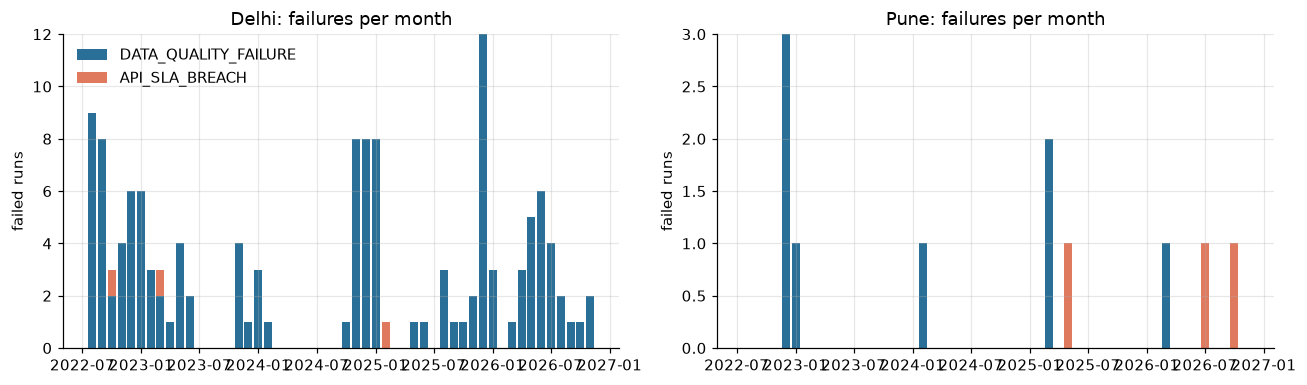

In [2]:
def find_file(cands):
    for c in cands:
        if Path(c).exists():
            return c
    raise FileNotFoundError(f"None of these files found: {cands}. Put the CSV next to this notebook.")

def load_city(city):
    path = find_file(DATA_CANDIDATES[city])
    df = pd.read_csv(path)
    df["run_date"] = pd.to_datetime(df["run_date"]).dt.normalize()
    df = (df.sort_values(["run_date", "start_time"])
            .drop_duplicates("run_date", keep="last")   # one run per day
            .reset_index(drop=True))
    ft = df["failure_type"].fillna("")
    wr = df["warning_reason"].fillna("")
    df["is_fail"]      = (df["overall_status"].str.upper() == "FAIL").astype(int)
    df["dq_fail"]      = (ft == "DATA_QUALITY_FAILURE").astype(int)
    df["sla_fail"]     = (ft == "API_SLA_BREACH").astype(int)
    df["hazard_warn"]  = wr.str.contains("HAZARD").astype(int)
    df["runtime_warn"] = wr.str.contains("HIGH_RUNTIME").astype(int)
    df["city"] = city
    print(f"{city}: loaded {path}")
    return df

raw = {c: load_city(c) for c in DATA_CANDIDATES}

audit = []
for c, d in raw.items():
    full = pd.date_range(d.run_date.min(), d.run_date.max())
    audit.append({"city": c, "runs": len(d), "from": d.run_date.min().date(), "to": d.run_date.max().date(),
                  "missing_days": len(full.difference(d.run_date)),
                  "FAIL": d.is_fail.sum(), "fail_%": round(100 * d.is_fail.mean(), 2),
                  "DATA_QUALITY": d.dq_fail.sum(), "API_SLA": d.sla_fail.sum(),
                  "hazard_warning_days": d.hazard_warn.sum()})
audit = pd.DataFrame(audit); display(audit)
audit.to_csv(OUT / "01_data_audit.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for ax, (c, d) in zip(axes, raw.items()):
    m = d.set_index("run_date")[["dq_fail", "sla_fail"]].resample("MS").sum()
    ax.bar(m.index, m.dq_fail, width=25, color=C_MAIN, label="DATA_QUALITY_FAILURE")
    ax.bar(m.index, m.sla_fail, width=25, bottom=m.dq_fail, color=C_ALT, label="API_SLA_BREACH")
    ax.set_title(f"{c}: failures per month"); ax.set_ylabel("failed runs")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT / "fig01_failures_per_month.png"); plt.show()

## 2. Target and features (leakage-free by construction)
**Target:** `y_next = 1` if the **next day's** run is a `DATA_QUALITY_FAILURE` (the data-driven failure type).
Features are computed only from runs **up to and including today**, so nothing from tomorrow leaks in.

Three feature groups (used for the infra-vs-data ablation):
- **DATA** — data-centric signals: drift (PSI), hourly jumps, stagnation, invalid values, freshness, completeness, and their rolling trends. Includes `hazard_exceed_count` as a *feature* (a leading signal), never as the label — high real-world pollution is a warning, not a failure.
- **INFRA** — operational signals: run duration, API latency and their trends, retries, runtime warnings.
- **HISTORY** — recent failure history (today failed? failures in last 3/7 days, days since last failure).

Plus month (sin/cos) to capture seasonality.

With only ~130 failures, a **compact set of ~23 signals** generalises better than all 53 engineered columns
(checked with time-series cross-validation on the training period only). Set `USE_COMPACT = False` to use everything.

In [3]:
DATA_RAW  = ["drift_psi_mean", "drift_psi_max",
             "max_hourly_jump", "max_stagnation_run", "invalid_value_count",
             "coverage_percent", "missing_value_rate_percent", "core_missing_value_rate_percent",
             "duplicate_count", "missing_intervals", "max_gap_minutes", "rows_vs_expected_ratio",
             "row_shortfall", "freshness_lag_hours", "hazard_exceed_count"]
INFRA_RAW = ["duration_seconds", "duration_roll3_mean", "duration_roll7_std", "duration_vs_baseline",
             "api_latency_mean", "api_latency_max", "api_latency_p95", "api_latency_vs_baseline",
             "api_latency_roll3_mean", "api_latency_roll7_std", "retry_count"]
TREND_COLS = ["drift_psi_mean", "max_hourly_jump", "invalid_value_count"]

def build_features(d):
    d = d.sort_values("run_date").reset_index(drop=True)
    F = pd.DataFrame(index=d.index)
    groups = {"DATA": [], "INFRA": [], "HISTORY": [], "CALENDAR": []}
    for c in DATA_RAW:
        if c in d: F[c] = d[c]; groups["DATA"].append(c)
    for c in TREND_COLS:                                  # causal rolling trends (past + today only)
        if c in d:
            for w in (3, 7):
                F[f"{c}_roll{w}"] = d[c].rolling(w, min_periods=1).mean(); groups["DATA"].append(f"{c}_roll{w}")
            F[f"{c}_vs7"] = d[c] - d[c].rolling(7, min_periods=1).mean(); groups["DATA"].append(f"{c}_vs7")
    for c in INFRA_RAW:
        if c in d: F[c] = d[c]; groups["INFRA"].append(c)
    F["runtime_warn_today"] = d["runtime_warn"]
    F["runtime_warn_last7"] = d["runtime_warn"].rolling(7, min_periods=1).sum()
    groups["INFRA"] += ["runtime_warn_today", "runtime_warn_last7"]

    F["dq_fail_today"]  = d["dq_fail"]
    F["sla_fail_today"] = d["sla_fail"]
    F["fails_last3"] = d["is_fail"].rolling(3, min_periods=1).sum()
    F["fails_last7"] = d["is_fail"].rolling(7, min_periods=1).sum()
    last = d["run_date"].where(d["is_fail"] == 1).ffill()
    F["days_since_fail"] = (d["run_date"] - last).dt.days.fillna(365).clip(upper=365)
    groups["HISTORY"] += ["dq_fail_today", "sla_fail_today", "fails_last3", "fails_last7", "days_since_fail"]

    m = d["run_date"].dt.month
    F["month_sin"], F["month_cos"] = np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12)
    groups["CALENDAR"] += ["month_sin", "month_cos"]

    # Targets: tomorrow's outcome (shift -1). Last day has no "tomorrow" -> NaN.
    T = pd.DataFrame({"run_date": d["run_date"],
                      "y_dq_next":  d["dq_fail"].shift(-1),
                      "y_sla_next": d["sla_fail"].shift(-1),
                      "y_any_next": d["is_fail"].shift(-1),
                      "dq_today":   d["dq_fail"]})
    return F, T, groups

feat, targ, GROUPS = {}, {}, None
for c, d in raw.items():
    feat[c], targ[c], GROUPS = build_features(d)

FULL_GROUPS = GROUPS
COMPACT = {
    "DATA":     ["max_hourly_jump", "drift_psi_mean", "drift_psi_max",
                 "max_stagnation_run", "invalid_value_count", "max_hourly_jump_roll7",
                 "drift_psi_mean_roll7", "freshness_lag_hours", "rows_vs_expected_ratio",
                 "hazard_exceed_count"],
    "INFRA":    ["duration_seconds", "duration_vs_baseline", "api_latency_mean", "api_latency_vs_baseline",
                 "api_latency_roll7_std", "runtime_warn_last7"],
    "HISTORY":  ["dq_fail_today", "sla_fail_today", "fails_last7", "days_since_fail"],
    "CALENDAR": ["month_sin", "month_cos"]}
if USE_COMPACT:
    GROUPS = {g: [c for c in cs if c in feat[MAIN_CITY]] for g, cs in COMPACT.items()}
ALL_FEATS = sum(GROUPS.values(), [])
FEATURE_SETS = {
    "INFRA only":            GROUPS["INFRA"],
    "HISTORY only":          GROUPS["HISTORY"],
    "DATA only":             GROUPS["DATA"],
    "DATA + HISTORY":        GROUPS["DATA"] + GROUPS["HISTORY"] + GROUPS["CALENDAR"],
    "ALL (data+infra+hist)": ALL_FEATS,
}
print({g: len(v) for g, v in GROUPS.items()}, "| total features:", len(ALL_FEATS))

{'DATA': 10, 'INFRA': 6, 'HISTORY': 4, 'CALENDAR': 2} | total features: 22


## 3. Chronological split (main city)
Train on the oldest 50% of days, tune on the next 25% (validation — a full year, so it contains enough failures), report once on the newest 25% (test).
Never shuffled — the model only ever sees the past. The test window must contain at least 30 failures.

In [4]:
def chrono_split(F, T, target="y_dq_next"):
    ok = T[target].notna()
    X, y, dates = F[ok].reset_index(drop=True), T.loc[ok, target].astype(int).reset_index(drop=True), T.loc[ok, "run_date"].reset_index(drop=True)
    n = len(X); a, b = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
    return (X[:a], y[:a], dates[:a]), (X[a:b], y[a:b], dates[a:b]), (X[b:], y[b:], dates[b:])

(Xtr, ytr, dtr), (Xva, yva, dva), (Xte, yte, dte) = chrono_split(feat[MAIN_CITY], targ[MAIN_CITY])
split_info = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "from": [dtr.min().date(), dva.min().date(), dte.min().date()],
    "to":   [dtr.max().date(), dva.max().date(), dte.max().date()],
    "days": [len(ytr), len(yva), len(yte)],
    "failures_next_day": [ytr.sum(), yva.sum(), yte.sum()],
    "rate_%": [round(100 * ytr.mean(), 1), round(100 * yva.mean(), 1), round(100 * yte.mean(), 1)]})
display(split_info); split_info.to_csv(OUT / "03_split.csv", index=False)
if yva.sum() < MIN_VAL_FAILURES:
    print(f"WARNING: only {yva.sum()} failures in validation (< {MIN_VAL_FAILURES}); model choice/threshold will be noisy.")
if yte.sum() < MIN_TEST_FAILURES:
    print(f"WARNING: only {yte.sum()} failures in test (< {MIN_TEST_FAILURES}). Increase the test share.")
else:
    print(f"OK: {yte.sum()} failures in the test window (>= {MIN_TEST_FAILURES}).")

,split,from,to,days,failures_next_day,rate_%
0,train,2022-08-05,2024-09-20,778,56,7.2
1,validation,2024-09-21,2025-10-14,389,31,8.0
2,test,2025-10-15,2026-11-07,389,43,11.1


OK: 43 failures in the test window (>= 30).


### Helper functions
Model factory, imbalance handling (SMOTE applied **only to training folds**), Platt calibration, metrics and bootstrap confidence intervals.

In [5]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve)

def prepare(X_fit, *others, cols=None):
    # Keep chosen columns, drop columns constant in the fitting data, impute with fitting medians.
    cols = [c for c in (cols or X_fit.columns) if c in X_fit]
    cols = [c for c in cols if X_fit[c].nunique(dropna=True) > 1]
    med = X_fit[cols].median()
    out = [X_fit[cols].fillna(med)] + [o[cols].fillna(med) for o in others]
    return out, cols

def simple_smote(X, y, k=5, seed=RANDOM_STATE):
    # Minimal SMOTE (used only if imbalanced-learn is not installed).
    rng = np.random.default_rng(seed)
    Xa, ya = np.asarray(X, float), np.asarray(y)
    mino = Xa[ya == 1]; n_new = int((ya == 0).sum() - (ya == 1).sum())
    if len(mino) < 2 or n_new <= 0:
        return X, y
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(mino))).fit(mino)
    _, idx = nn.kneighbors(mino)
    base = rng.integers(0, len(mino), n_new)
    nb = idx[base, rng.integers(1, idx.shape[1], n_new)]
    new = mino[base] + rng.random((n_new, 1)) * (mino[nb] - mino[base])
    Xn = pd.DataFrame(np.vstack([Xa, new]), columns=X.columns)
    return Xn, pd.Series(np.r_[ya, np.ones(n_new, int)])

def resample(X, y, imbalance):
    if imbalance not in ("smote", "both") or y.sum() < 2:
        return X, y
    if HAS_IMBLEARN:
        k = int(min(5, y.sum() - 1))
        Xr, yr = SMOTE(k_neighbors=k, random_state=RANDOM_STATE).fit_resample(X, y)
        return pd.DataFrame(Xr, columns=X.columns), pd.Series(yr)
    return simple_smote(X, y)

def make_model(name, imbalance, y):
    weighted = imbalance in ("weights", "both")
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=500, min_samples_leaf=20, max_depth=6, max_features="sqrt", n_jobs=-1,
                                      class_weight="balanced_subsample" if weighted else None, random_state=RANDOM_STATE)
    if name == "XGBoost":
        if HAS_XGB:
            spw = float((y == 0).sum() / max(1, (y == 1).sum())) if weighted else 1.0
            return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.03, subsample=0.8,
                                 colsample_bytree=0.8, min_child_weight=10, reg_lambda=2.0, eval_metric="aucpr",
                                 scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=-1)
        # fallback: sklearn's gradient boosting (same family)
        return HistGradientBoostingClassifier(max_iter=150, learning_rate=0.03, max_depth=3, min_samples_leaf=30, l2_regularization=1.0,
                                              class_weight="balanced" if weighted else None, random_state=RANDOM_STATE)
    if name == "LogisticRegression":   # interpretable linear reference model
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000,
                             class_weight="balanced" if weighted else None))
    raise ValueError(name)

def fit_model(Xf, yf, name, imbalance):
    Xr, yr = resample(Xf, yf, imbalance)
    return make_model(name, imbalance, yr).fit(Xr, yr)

def proba(m, X):
    return m.predict_proba(X)[:, 1]

class Platt:
    # Platt (sigmoid) calibration fitted on held-out, NOT resampled, data.
    def fit(self, p, y):
        self.lr = LogisticRegression(C=1e3).fit(self._z(p), y); return self
    def _z(self, p):
        p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p)).reshape(-1, 1)
    def transform(self, p):
        return self.lr.predict_proba(self._z(p))[:, 1]

def safe_auc(f, y, p):
    y = np.asarray(y)
    return f(y, p) if 0 < y.sum() < len(y) else np.nan

def boot_ci(y, p, metric=average_precision_score, n=N_BOOT, seed=RANDOM_STATE):
    y, p = np.asarray(y), np.asarray(p); rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            vals.append(metric(y[i], p[i]))
    return (np.percentile(vals, 2.5), np.percentile(vals, 97.5)) if vals else (np.nan, np.nan)

def score_row(name, y, p, thr=None):
    lo, hi = boot_ci(y, p)
    r = {"model": name, "PR-AUC": safe_auc(average_precision_score, y, p), "PR-AUC 95% CI": f"[{lo:.3f}, {hi:.3f}]",
         "ROC-AUC": safe_auc(roc_auc_score, y, p), "base rate": np.mean(y)}
    r["lift"] = r["PR-AUC"] / r["base rate"] if r["base rate"] else np.nan
    if thr is not None:
        yh = (np.asarray(p) >= thr).astype(int)
        r.update({"precision": precision_score(y, yh, zero_division=0), "recall": recall_score(y, yh, zero_division=0),
                  "F1": f1_score(y, yh, zero_division=0)})
    return r

def best_threshold(y, p):
    # Threshold that maximises F1 on the validation set.
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-9, None)
    i = int(np.nanargmax(f1[:-1])) if len(th) else 0
    return float(th[i]) if len(th) else 0.5
print("helpers ready")

helpers ready


## 4. Model selection + class-imbalance ablation
Three models (Random Forest, XGBoost, and Logistic Regression as an interpretable linear reference) × four imbalance strategies, all fitted on **train** and compared on **validation** PR-AUC.
The winner is chosen here — the test set is not touched.

20 usable features after dropping constant columns


,model,algo,imbalance,val PR-AUC,val ROC-AUC
0,RandomForest,RandomForest,none,0.171,0.726
1,LogisticRegression,LogisticRegression,weights,0.161,0.637
2,RandomForest,RandomForest,weights,0.141,0.706
3,XGBoost,XGBoost,none,0.140,0.707
4,LogisticRegression,LogisticRegression,none,0.118,0.609
5,RandomForest,RandomForest,smote,0.114,0.655
6,RandomForest,RandomForest,both,0.114,0.656
7,XGBoost,XGBoost,smote,0.112,0.647
8,XGBoost,XGBoost,both,0.112,0.647
9,XGBoost,XGBoost,weights,0.110,0.652


Selected: RandomForest with imbalance = 'none' (by validation PR-AUC)


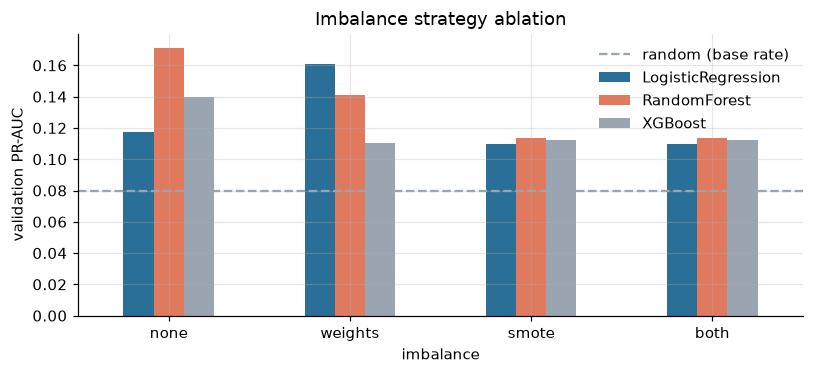

In [6]:
(Xtr_p, Xva_p, Xte_p), COLS = prepare(Xtr, Xva, Xte, cols=ALL_FEATS)
print(f"{len(COLS)} usable features after dropping constant columns")

ablation = []
for name in ["RandomForest", "XGBoost", "LogisticRegression"]:
    for imb in ["none", "weights", "smote", "both"]:
        m = fit_model(Xtr_p, ytr, name, imb)
        pv = proba(m, Xva_p)
        ablation.append({"model": name if (name != "XGBoost" or HAS_XGB) else "GradBoost (fallback)",
                         "algo": name, "imbalance": imb,
                         "val PR-AUC": average_precision_score(yva, pv), "val ROC-AUC": roc_auc_score(yva, pv)})
ablation = pd.DataFrame(ablation).sort_values("val PR-AUC", ascending=False).reset_index(drop=True)
display(ablation.round(3)); ablation.to_csv(OUT / "04_imbalance_ablation.csv", index=False)

BEST_ALGO, BEST_IMB = ablation.loc[0, "algo"], ablation.loc[0, "imbalance"]
print(f"Selected: {ablation.loc[0, 'model']} with imbalance = '{BEST_IMB}' (by validation PR-AUC)")

piv = ablation.pivot(index="imbalance", columns="model", values="val PR-AUC").loc[["none", "weights", "smote", "both"]]
ax = piv.plot.bar(figsize=(7.5, 3.5), color=[C_MAIN, C_ALT, C_GREY], rot=0)
ax.axhline(yva.mean(), ls="--", color=C_GREY, label="random (base rate)")
ax.set_ylabel("validation PR-AUC"); ax.set_title("Imbalance strategy ablation"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT / "fig04_imbalance_ablation.png"); plt.show()

## 5. Probability calibration
So that "risk = 0.40" really means about a 40% chance. Platt scaling is fitted on the **validation** set, which is **not** resampled (SMOTE never touches it).
Platt is used rather than isotonic because isotonic over-fits at this data size.

,,test Brier score (lower = better),test PR-AUC
0,before calibration,0.0945,0.2291
1,after calibration,0.0931,0.2291


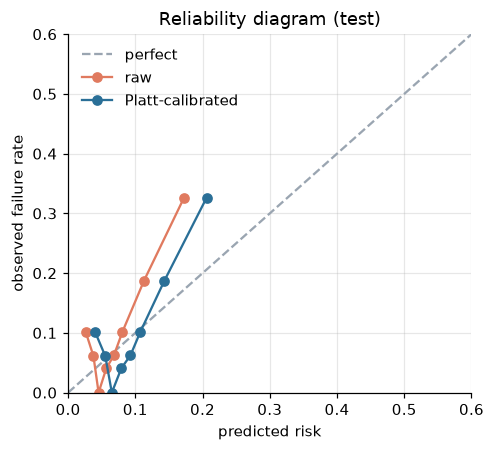

In [7]:
MODEL = fit_model(Xtr_p, ytr, BEST_ALGO, BEST_IMB)
p_va_raw, p_te_raw = proba(MODEL, Xva_p), proba(MODEL, Xte_p)
CAL = Platt().fit(p_va_raw, yva)
p_va, p_te = CAL.transform(p_va_raw), CAL.transform(p_te_raw)

cal_tbl = pd.DataFrame({"": ["before calibration", "after calibration"],
                        "test Brier score (lower = better)": [brier_score_loss(yte, p_te_raw), brier_score_loss(yte, p_te)],
                        "test PR-AUC": [average_precision_score(yte, p_te_raw), average_precision_score(yte, p_te)]})
display(cal_tbl.round(4)); cal_tbl.to_csv(OUT / "05_calibration.csv", index=False)

def reliability(ax, y, p, label, color, bins=8):
    q = pd.qcut(p, q=bins, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": np.asarray(y)}).groupby(q, observed=True).mean()
    ax.plot(g.p, g.y, "o-", color=color, label=label)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], "--", color=C_GREY, label="perfect")
reliability(ax, yte, p_te_raw, "raw", C_ALT); reliability(ax, yte, p_te, "Platt-calibrated", C_MAIN)
lim = max(0.6, float(np.max(p_te_raw)) + 0.05)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("predicted risk"); ax.set_ylabel("observed failure rate"); ax.set_title("Reliability diagram (test)")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(OUT / "fig05_reliability.png"); plt.show()

## 6. Baselines and the infra-vs-data ablation (proves Novelty 2)
All rows are evaluated on the **same test window**, with 95% bootstrap confidence intervals.
- **Dummy** — always the base rate (floor).
- **Persistence rule** — "warn tomorrow if today failed".
- **Feature-group models** — same algorithm, different signal families.

If **DATA** beats **INFRA**, data-centric signals carry predictive power that operational signals do not.
If the full model beats the rules, ML adds value beyond a one-line heuristic.

,model,PR-AUC,PR-AUC 95% CI,ROC-AUC,base rate,lift,precision,recall,F1
0,Dummy (base rate),0.111,"[0.085, 0.141]",0.500,0.111,1.000,NaN,NaN,NaN
1,Rule: persistence (today failed),0.169,"[0.111, 0.253]",0.608,0.111,1.525,0.302,0.302,0.302
2,ML: INFRA only,0.116,"[0.078, 0.196]",0.482,0.111,1.048,0.112,0.674,0.192
3,ML: HISTORY only,0.196,"[0.126, 0.308]",0.593,0.111,1.769,0.346,0.209,0.261
4,ML: DATA only,0.217,"[0.144, 0.340]",0.664,0.111,1.966,0.219,0.488,0.302
5,ML: DATA + HISTORY,0.220,"[0.147, 0.330]",0.678,0.111,1.987,0.233,0.488,0.316
6,ML: ALL (data+infra+hist),0.229,"[0.157, 0.347]",0.695,0.111,2.073,0.248,0.581,0.347


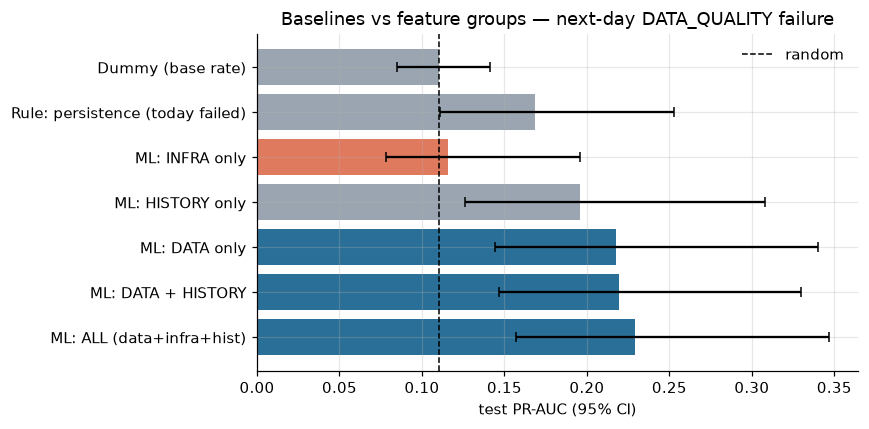

In [8]:
rows = []
rows.append(score_row("Dummy (base rate)", yte, np.full(len(yte), ytr.mean())))
rows.append(score_row("Rule: persistence (today failed)", yte, Xte["dq_fail_today"].values, thr=0.5))

group_preds = {}
for gname, cols in FEATURE_SETS.items():
    (a, b, c), used = prepare(Xtr, Xva, Xte, cols=cols)
    if not used:
        continue
    m = fit_model(a, ytr, BEST_ALGO, BEST_IMB)
    cal = Platt().fit(proba(m, b), yva)
    pv, pt = cal.transform(proba(m, b)), cal.transform(proba(m, c))
    group_preds[gname] = pt
    rows.append(score_row(f"ML: {gname}", yte, pt, thr=best_threshold(yva, pv)))

baseline_tbl = pd.DataFrame(rows)
display(baseline_tbl.round(3)); baseline_tbl.to_csv(OUT / "06_baselines_and_ablation.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
bt = baseline_tbl.iloc[::-1]
ci = bt["PR-AUC 95% CI"].str.strip("[]").str.split(", ", expand=True).astype(float)
err = np.vstack([bt["PR-AUC"] - ci[0], ci[1] - bt["PR-AUC"]])
colors = [C_MAIN if "DATA" in n or "ALL" in n else (C_ALT if "INFRA" in n else C_GREY) for n in bt["model"]]
ax.barh(bt["model"], bt["PR-AUC"], xerr=err, color=colors, capsize=3)
ax.axvline(yte.mean(), ls="--", color="k", lw=1, label="random")
ax.set_xlabel("test PR-AUC (95% CI)"); ax.set_title("Baselines vs feature groups — next-day DATA_QUALITY failure")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(OUT / "fig06_infra_vs_data.png"); plt.show()

## 7. Operating point — what an operator would actually see
The alarm threshold is chosen on **validation** (max F1) and then applied unchanged to the test window.

,threshold (from validation),failures in test,caught 1 day ahead (TP),missed (FN),false alarms (FP),recall,precision,false alarms / month,alarms / month
0,0.116,43,25,18,76,0.581,0.248,5.955,7.913


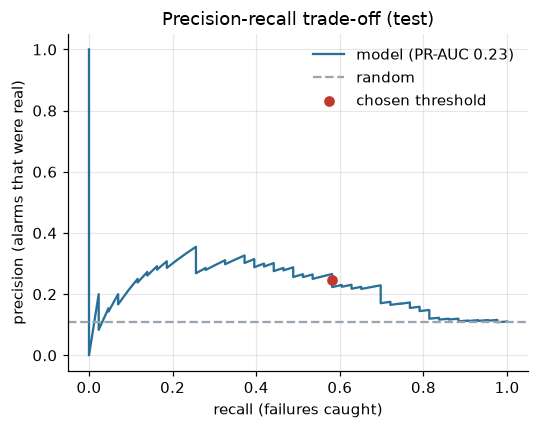

In [9]:
THRESHOLD = best_threshold(yva, p_va)
yhat = (p_te >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, yhat, labels=[0, 1]).ravel()
months = max(1.0, (dte.max() - dte.min()).days / 30.4)
op = pd.DataFrame([{"threshold (from validation)": THRESHOLD, "failures in test": int(yte.sum()),
                    "caught 1 day ahead (TP)": tp, "missed (FN)": fn, "false alarms (FP)": fp,
                    "recall": tp / max(1, tp + fn), "precision": tp / max(1, tp + fp),
                    "false alarms / month": fp / months, "alarms / month": (tp + fp) / months}])
display(op.round(3)); op.to_csv(OUT / "07_operating_point.csv", index=False)

pr, rc, _ = precision_recall_curve(yte, p_te)
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(rc, pr, color=C_MAIN, label=f"model (PR-AUC {average_precision_score(yte, p_te):.2f})")
ax.axhline(yte.mean(), ls="--", color=C_GREY, label="random")
ax.scatter([op['recall'][0]], [op['precision'][0]], color=C_BAD, zorder=3, label="chosen threshold")
ax.set_xlabel("recall (failures caught)"); ax.set_ylabel("precision (alarms that were real)")
ax.set_title("Precision-recall trade-off (test)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT / "fig07_pr_curve.png"); plt.show()

## 8. Lead time (Novelty 4)
Each run = one day, so the basic lead time is **1 day**. Two richer views:
1. **Horizon curve** — retrain to predict "a failure within the next *k* days" (k = 1…7) and see how predictability changes as we ask for earlier warning.
2. **Alarm run-up** — for every test failure, how many consecutive days before it the alarm was already on.

,horizon_days,test PR-AUC,CI_lo,CI_hi,base rate,lift,ROC-AUC
0,1,0.229,0.157,0.347,0.111,2.073,0.695
1,2,0.273,0.208,0.378,0.188,1.453,0.589
2,3,0.341,0.266,0.447,0.254,1.339,0.562
3,4,0.410,0.341,0.508,0.316,1.295,0.573
4,5,0.487,0.415,0.573,0.369,1.320,0.566
5,6,0.470,0.403,0.560,0.412,1.139,0.525
6,7,0.480,0.415,0.562,0.454,1.059,0.496


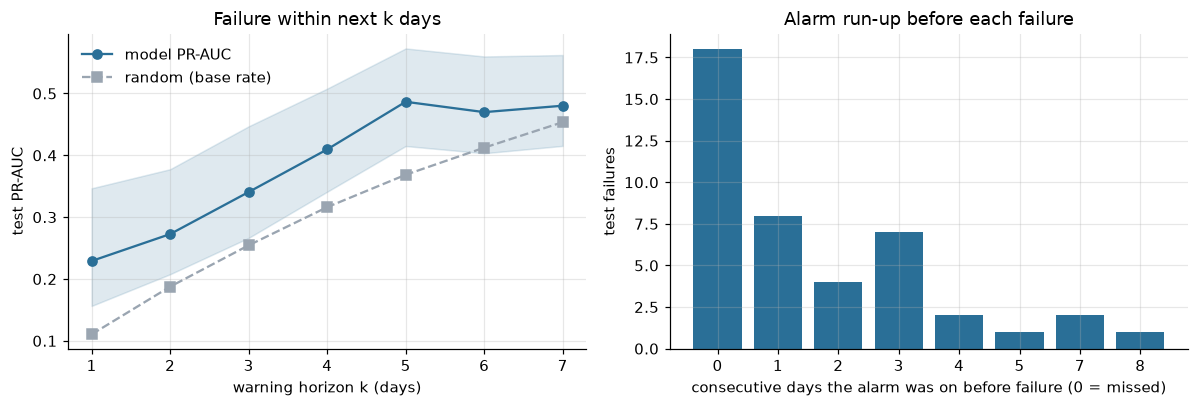

Failures warned >= 1 day ahead: 58%; >= 2 days: 40%; >= 3 days: 30%


In [10]:
def horizon_target(d_dq, k):
    s = pd.concat([d_dq.shift(-i) for i in range(1, k + 1)], axis=1)
    return s.max(axis=1).where(s.notna().sum(axis=1) == k)

horizon = []
dq_main = raw[MAIN_CITY].sort_values("run_date").reset_index(drop=True)["dq_fail"]
for k in range(1, 8):
    Tk = targ[MAIN_CITY].copy(); Tk["yk"] = horizon_target(dq_main, k)
    (a, ya, _), (b, yb, _), (c, yc, _) = chrono_split(feat[MAIN_CITY], Tk, "yk")
    (a, b, c), _ = prepare(a, b, c, cols=ALL_FEATS)
    m = fit_model(a, ya, BEST_ALGO, BEST_IMB)
    pc = proba(m, c)
    lo, hi = boot_ci(yc, pc)
    horizon.append({"horizon_days": k, "test PR-AUC": average_precision_score(yc, pc), "CI_lo": lo, "CI_hi": hi,
                    "base rate": yc.mean(), "lift": average_precision_score(yc, pc) / yc.mean(),
                    "ROC-AUC": roc_auc_score(yc, pc)})
horizon = pd.DataFrame(horizon); display(horizon.round(3)); horizon.to_csv(OUT / "08_horizon_curve.csv", index=False)

# Alarm run-up: prediction made on day t targets day t+1
alarm = pd.Series((p_te >= THRESHOLD).astype(int), index=dte.values)
fail_days = dte[yte.values == 1] + pd.Timedelta(days=1)            # the failure dates
runup = []
for f in fail_days:
    n = 0
    while (f - pd.Timedelta(days=n + 1)) in alarm.index and alarm[f - pd.Timedelta(days=n + 1)] == 1:
        n += 1
    runup.append(n)
runup = pd.Series(runup, name="days alarm was on before the failure")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.fill_between(horizon.horizon_days, horizon.CI_lo, horizon.CI_hi, color=C_MAIN, alpha=0.15)
ax.plot(horizon.horizon_days, horizon["test PR-AUC"], "o-", color=C_MAIN, label="model PR-AUC")
ax.plot(horizon.horizon_days, horizon["base rate"], "s--", color=C_GREY, label="random (base rate)")
ax.set_xlabel("warning horizon k (days)"); ax.set_ylabel("test PR-AUC"); ax.set_title("Failure within next k days")
ax.legend(frameon=False)
ax = axes[1]
vc = runup.value_counts().sort_index()
ax.bar(vc.index.astype(str), vc.values, color=C_MAIN)
ax.set_xlabel("consecutive days the alarm was on before failure (0 = missed)"); ax.set_ylabel("test failures")
ax.set_title("Alarm run-up before each failure")
plt.tight_layout(); plt.savefig(OUT / "fig08_lead_time.png"); plt.show()
print(f"Failures warned >= 1 day ahead: {(runup >= 1).mean():.0%}; >= 2 days: {(runup >= 2).mean():.0%}; >= 3 days: {(runup >= 3).mean():.0%}")

## 9. Per-failure-type predictability map ★ (headline — Novelty 1)
Same method for every (city, failure type) with at least 5 events: expanding-window time-series cross-validation
(always train on the past, predict the next block), pooled out-of-fold predictions, bootstrap CIs.

**Lift** = PR-AUC ÷ base rate. Lift ≈ 1 means *no better than chance* → that failure type carries no early signal in the data.

*Note for the write-up:* `API_SLA_BREACH` depends on API speed at the moment the historical replay ran, i.e. it is externally driven.

,city,failure type,events,evaluated events,PR-AUC,PR-AUC 95% CI,base rate,lift,lift CI low,ROC-AUC,verdict
0,Delhi,DATA_QUALITY_FAILURE,130,89.0,0.156,"[0.111, 0.226]",0.069,2.270,1.618,0.683,PREDICTABLE (lift CI > 1)
1,Delhi,API_SLA_BREACH,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too few events to test
2,Pune,DATA_QUALITY_FAILURE,8,4.0,0.004,"[0.002, 0.011]",0.003,1.431,0.637,0.587,NOT reliably predictable
3,Pune,API_SLA_BREACH,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too few events to test


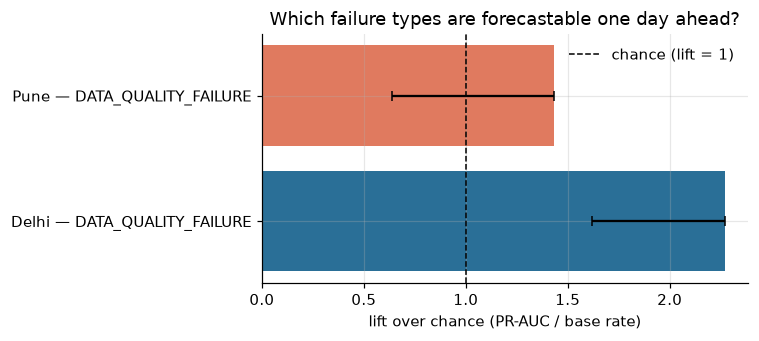

In [11]:
from sklearn.model_selection import TimeSeriesSplit

def oof_predict(F, y, n_splits=5):
    ok = y.notna(); X, yy = F[ok].reset_index(drop=True), y[ok].astype(int).reset_index(drop=True)
    p = pd.Series(np.nan, index=X.index)
    for tr, te in TimeSeriesSplit(n_splits=n_splits).split(X):
        if yy.iloc[tr].sum() < 3:
            continue                     # cannot learn from < 3 events
        (a, b), _ = prepare(X.iloc[tr], X.iloc[te], cols=ALL_FEATS)
        p.iloc[te] = proba(fit_model(a, yy.iloc[tr], BEST_ALGO, BEST_IMB), b)
    keep = p.notna()
    return yy[keep].values, p[keep].values

pmap = []
for city in raw:
    for tname, tcol in [("DATA_QUALITY_FAILURE", "y_dq_next"), ("API_SLA_BREACH", "y_sla_next")]:
        y = targ[city][tcol]
        if y.sum() < 5:
            pmap.append({"city": city, "failure type": tname, "events": int(y.sum()), "verdict": "too few events to test"})
            continue
        yy, pp = oof_predict(feat[city], y)
        if yy.sum() == 0:
            pmap.append({"city": city, "failure type": tname, "events": int(y.sum()), "verdict": "no events in evaluated folds"})
            continue
        r = score_row("", yy, pp); lo, hi = boot_ci(yy, pp)
        lift_lo = lo / r["base rate"]
        verdict = "PREDICTABLE (lift CI > 1)" if lift_lo > 1 else "NOT reliably predictable"
        pmap.append({"city": city, "failure type": tname, "events": int(y.sum()), "evaluated events": int(yy.sum()),
                     "PR-AUC": r["PR-AUC"], "PR-AUC 95% CI": r["PR-AUC 95% CI"], "base rate": r["base rate"],
                     "lift": r["lift"], "lift CI low": lift_lo, "ROC-AUC": r["ROC-AUC"], "verdict": verdict})
pmap = pd.DataFrame(pmap); display(pmap.round(3)); pmap.to_csv(OUT / "09_predictability_map.csv", index=False)

pm = pmap.dropna(subset=["lift"]) if "lift" in pmap else pmap.iloc[0:0]
if len(pm):
    fig, ax = plt.subplots(figsize=(7, 3.2))
    lab = pm["city"] + " — " + pm["failure type"]
    ax.barh(lab, pm["lift"], color=[C_MAIN if v.startswith("PRED") else C_ALT for v in pm["verdict"]])
    ax.errorbar(pm["lift"], lab, xerr=[pm["lift"] - pm["lift CI low"], np.zeros(len(pm))], fmt="none", ecolor="k", capsize=3)
    ax.axvline(1, ls="--", color="k", lw=1, label="chance (lift = 1)")
    ax.set_xlabel("lift over chance (PR-AUC / base rate)"); ax.set_title("Which failure types are forecastable one day ahead?")
    ax.legend(frameon=False); plt.tight_layout(); plt.savefig(OUT / "fig09_predictability_map.png"); plt.show()

## 10. Leakage-gap demonstration ★ (Novelty 5)
**INVALID BY DESIGN — shown only to expose the pitfall.** A common mistake is to predict a run's failure from columns logged
**in that same run** (`invalid_value_count`, `max_hourly_jump`, …). These columns are what *define* the failure, so the score is inflated.
We train that leaky model on the same split and put it next to the honest next-day model.

,model,PR-AUC,PR-AUC 95% CI,ROC-AUC,base rate,lift
0,LEAKY: same-run features -> same-run failure ...,1.000,"[1.000, 1.000]",1.000,0.111,9.047
1,HONEST: today's features -> tomorrow's failure,0.229,"[0.157, 0.347]",0.695,0.111,2.073


Leakage inflates PR-AUC by 0.771 (1.000 vs 0.229).


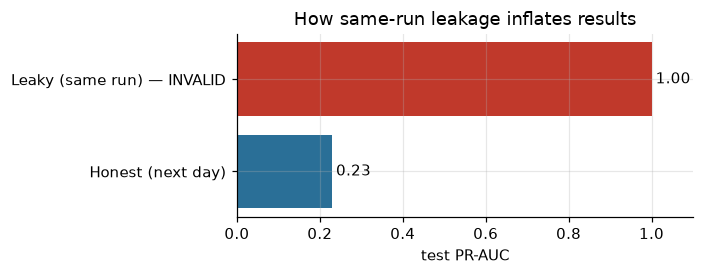

In [12]:
LEAKY_COLS = [c for c in DATA_RAW + INFRA_RAW if c in Xtr]          # same-run log columns
yl_tr, yl_va, yl_te = (targ[MAIN_CITY]["dq_today"].iloc[s.index].astype(int).values for s in (ytr, yva, yte))
(a, b, c), _ = prepare(Xtr, Xva, Xte, cols=LEAKY_COLS)
leaky = fit_model(a, yl_tr, BEST_ALGO, BEST_IMB)
pl = proba(leaky, c)

leak_tbl = pd.DataFrame([
    {**score_row("LEAKY: same-run features -> same-run failure  (INVALID)", yl_te, pl)},
    {**score_row("HONEST: today's features -> tomorrow's failure", yte, p_te)}])
display(leak_tbl.round(3)); leak_tbl.to_csv(OUT / "10_leakage_gap.csv", index=False)
gap = leak_tbl.loc[0, "PR-AUC"] - leak_tbl.loc[1, "PR-AUC"]
print(f"Leakage inflates PR-AUC by {gap:.3f} ({leak_tbl.loc[0,'PR-AUC']:.3f} vs {leak_tbl.loc[1,'PR-AUC']:.3f}).")

fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh(["Honest (next day)", "Leaky (same run) — INVALID"], leak_tbl["PR-AUC"][::-1].values, color=[C_MAIN, C_BAD])
for i, v in enumerate(leak_tbl["PR-AUC"][::-1].values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set_xlim(0, 1.1); ax.set_xlabel("test PR-AUC"); ax.set_title("How same-run leakage inflates results")
plt.tight_layout(); plt.savefig(OUT / "fig10_leakage_gap.png"); plt.show()

## 11. Cross-source validation (supporting evidence)
Train on all of one city, test on all of the other (both directions), for next-day `DATA_QUALITY_FAILURE`.
Framing for the thesis: *cross-source under a shared schema* — a mild out-of-distribution check, not domain transfer.
Pune has very few data-quality failures, so its confidence intervals will be wide.

In [13]:
def all_xy(city, tcol="y_dq_next"):
    ok = targ[city][tcol].notna()
    return feat[city][ok].reset_index(drop=True), targ[city].loc[ok, tcol].astype(int).reset_index(drop=True)

cross = [score_row(f"Within {MAIN_CITY} (time split, Section 5)", yte, p_te)]
for src, dst in [(MAIN_CITY, OTHER_CITY), (OTHER_CITY, MAIN_CITY)]:
    Xs, ys = all_xy(src); Xd, yd = all_xy(dst)
    if ys.sum() < 3 or yd.sum() == 0:
        cross.append({"model": f"Train {src} -> test {dst}", "note": "too few failures"}); continue
    (a, b), _ = prepare(Xs, Xd, cols=ALL_FEATS)
    pd_ = proba(fit_model(a, ys, BEST_ALGO, BEST_IMB), b)
    r = score_row(f"Train {src} ({ys.sum()} fails) -> test {dst} ({yd.sum()} fails)", yd, pd_); cross.append(r)
cross = pd.DataFrame(cross); display(cross.round(3)); cross.to_csv(OUT / "11_cross_source.csv", index=False)

,model,PR-AUC,PR-AUC 95% CI,ROC-AUC,base rate,lift
0,"Within Delhi (time split, Section 5)",0.229,"[0.157, 0.347]",0.695,0.111,2.073
1,Train Delhi (130 fails) -> test Pune (8 fails),0.245,"[0.011, 0.628]",0.579,0.005,47.684
2,Train Pune (8 fails) -> test Delhi (130 fails),0.161,"[0.126, 0.218]",0.688,0.084,1.923


## 12. Explainability
Global view: which signals drive next-day failure risk (SHAP if installed; otherwise permutation importance on the test set).
Per-prediction explanations are used inside `predict_failure` in Section 13.

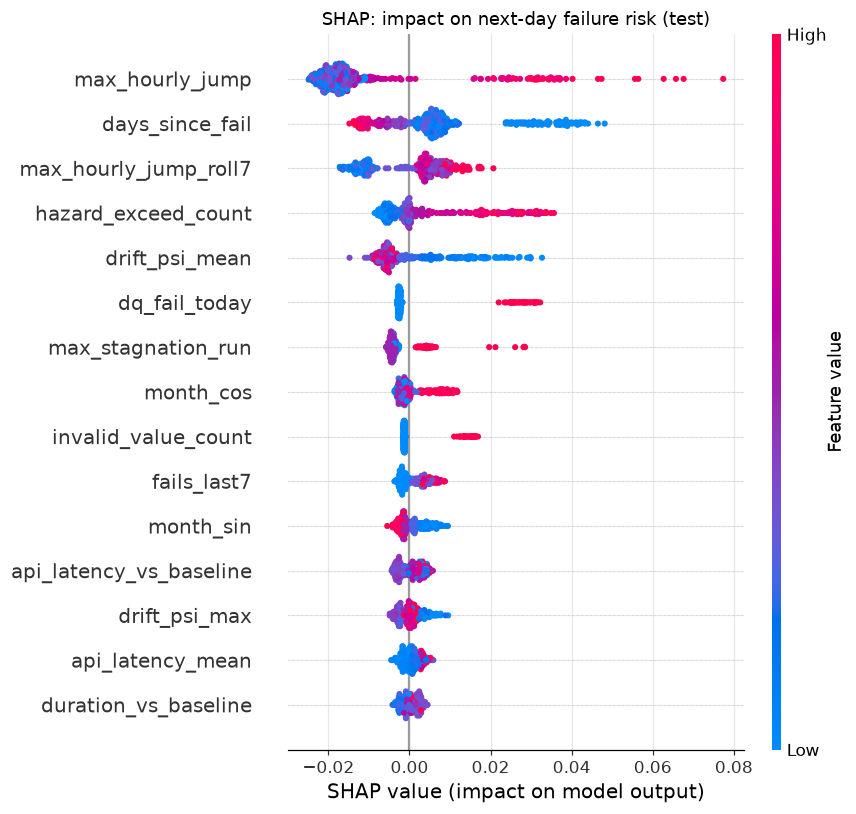

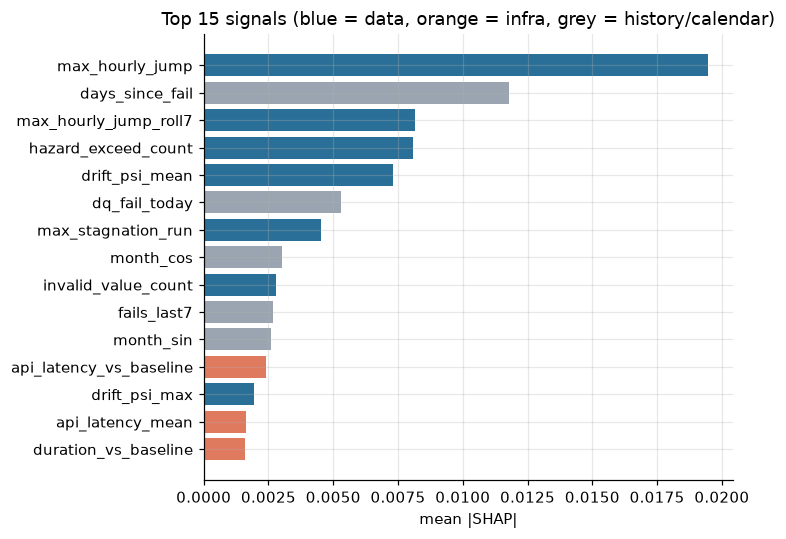

Importance share by group:


group
CALENDAR    0.065
DATA        0.615
HISTORY     0.226
INFRA       0.094
Name: importance, dtype: float64

In [14]:
from sklearn.inspection import permutation_importance

def shap_values_for(model, X):
    sv = shap.TreeExplainer(model).shap_values(X)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

if HAS_SHAP:
    try:
        SV = shap_values_for(MODEL, Xte_p)
        imp = pd.Series(np.abs(SV).mean(0), index=COLS).sort_values(ascending=False)
        shap.summary_plot(SV, Xte_p, max_display=15, show=False)
        plt.title("SHAP: impact on next-day failure risk (test)"); plt.tight_layout()
        plt.savefig(OUT / "fig12_shap_summary.png", bbox_inches="tight"); plt.show()
        IMP_METHOD = "mean |SHAP|"
    except Exception as e:
        print("SHAP failed, using permutation importance:", e); HAS_SHAP = False
if not HAS_SHAP:
    pi = permutation_importance(MODEL, Xte_p, yte, scoring="average_precision", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=COLS).sort_values(ascending=False)
    IMP_METHOD = "permutation importance (drop in PR-AUC)"

top = imp.head(15)[::-1]
grp_of = {c: g for g, cs in GROUPS.items() for c in cs}
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=[{"DATA": C_MAIN, "INFRA": C_ALT}.get(grp_of.get(c), C_GREY) for c in top.index])
ax.set_xlabel(IMP_METHOD); ax.set_title("Top 15 signals (blue = data, orange = infra, grey = history/calendar)")
plt.tight_layout(); plt.savefig(OUT / "fig12_importance.png"); plt.show()
imp_tbl = imp.rename("importance").to_frame().assign(group=lambda t: t.index.map(grp_of))
imp_tbl.to_csv(OUT / "12_feature_importance.csv")
print("Importance share by group:"); pos = imp_tbl.assign(importance=imp_tbl["importance"].clip(lower=0))
display((pos.groupby("group")["importance"].sum() / pos["importance"].sum()).round(3))

## 13. `predict_failure(city, date)` — next-day early warning
Give a date → the model uses the run of the **day before** (and its history) to warn about that date.
Works for any date in the logs, and for the day after the last logged run (i.e. tomorrow).
The model was trained on Delhi; for Pune it is applied cross-source.

In [15]:
REF = Xtr_p   # reference for z-scores (fallback explanation)
NICE = {"max_hourly_jump": "large hourly jumps in readings", "drift_psi_mean": "data distribution drifting",
        "drift_psi_max": "one pollutant drifting strongly", "invalid_value_count": "invalid (negative) values",
        "dq_fail_today": "today's run already failed", "fails_last7": "several failures this week",
        "fails_last3": "failures in the last 3 days", "max_stagnation_run": "sensor flatlining",
        "days_since_fail": "time since the last failure",
        "month_sin": "season of the year", "month_cos": "season of the year",
        "max_hourly_jump_roll7": "jumps rising over the past week",
        "drift_psi_mean_roll7": "drift building over the past week", "duration_seconds": "slow pipeline run",
        "api_latency_mean": "slow API responses", "api_latency_vs_baseline": "API slower than usual",
        "duration_vs_baseline": "run slower than usual", "runtime_warn_last7": "recent high-runtime warnings"}

def explain_row(xrow, k=3):
    if HAS_SHAP:
        try:
            s = pd.Series(shap_values_for(MODEL, xrow)[0], index=COLS)
            return [(c, float(v)) for c, v in s.sort_values(ascending=False).head(k).items() if v > 0]
        except Exception:
            pass
    z = (xrow.iloc[0] - REF.mean()) / REF.std().replace(0, 1)
    cand = z[imp.head(12).index].sort_values(ascending=False)
    return [(c, float(v)) for c, v in cand.head(k).items() if v > 0.5]

def risk_level(p):
    return "HIGH" if p >= THRESHOLD else ("ELEVATED" if p >= THRESHOLD / 2 else "LOW")

def predict_failure(city, date, verbose=True):
    date = pd.Timestamp(date).normalize(); prev = date - pd.Timedelta(days=1)
    T, F = targ[city], feat[city]
    idx = T.index[T["run_date"] == prev]
    if len(idx) == 0:
        raise ValueError(f"No {city} run logged for {prev.date()} (needed to forecast {date.date()}).")
    xrow = F.loc[idx].reindex(columns=COLS).fillna(Xtr[COLS].median())   # same columns + imputation as training
    p = float(CAL.transform(proba(MODEL, xrow))[0])
    level = risk_level(p)
    reasons = explain_row(xrow)
    actual = raw[city].loc[raw[city].run_date == date, "failure_type"]
    actual = ("not yet run" if actual.empty else (actual.iloc[0] if isinstance(actual.iloc[0], str) and actual.iloc[0] else "SUCCESS"))
    if verbose:
        icon = {"HIGH": "⚠ ", "ELEVATED": "△ ", "LOW": "✅ "}[level]
        print(f"Prediction for {date.date()}  ({city}{', cross-source' if city != MAIN_CITY else ''})")
        print(f"  {icon}{level} RISK — failure probability = {p:.2f}  (alarm threshold {THRESHOLD:.2f})")
        print(f"  Likely type : DATA_QUALITY_FAILURE  (API_SLA_BREACH is not forecastable from data — see Section 9)")
        print(f"  Lead time   : 1 day ahead (uses the run of {prev.date()})")
        print(f"  Why         : " + ("; ".join(NICE.get(c, c) for c, _ in reasons) if reasons else "no strong risk signals"))
        print(f"  Actual      : {actual}")
    return {"city": city, "date": date.date(), "risk": round(p, 3), "level": level,
            "reasons": [c for c, _ in reasons], "actual": actual}

# Examples from the test window: a failure the model caught, a failure it missed, and tomorrow's forecast
tf = pd.DataFrame({"date": dte + pd.Timedelta(days=1), "y": yte.values, "p": p_te})
caught, missed = tf[(tf.y == 1) & (tf.p >= THRESHOLD)], tf[(tf.y == 1) & (tf.p < THRESHOLD)]
if len(caught):
    print("— A failure the model warned about —"); predict_failure(MAIN_CITY, caught.sort_values("p").iloc[-1]["date"]); print()
if len(missed):
    print("— A failure the model missed (no early signal) —"); predict_failure(MAIN_CITY, missed.iloc[len(missed) // 2]["date"]); print()
print("— Tomorrow —"); predict_failure(MAIN_CITY, raw[MAIN_CITY].run_date.max() + pd.Timedelta(days=1))

— A failure the model warned about —
Prediction for 2025-12-14  (Delhi)
  ⚠ HIGH RISK — failure probability = 0.24  (alarm threshold 0.12)
  Likely type : DATA_QUALITY_FAILURE  (API_SLA_BREACH is not forecastable from data — see Section 9)
  Lead time   : 1 day ahead (uses the run of 2025-12-13)
  Why         : large hourly jumps in readings; time since the last failure; today's run already failed
  Actual      : DATA_QUALITY_FAILURE

— A failure the model missed (no early signal) —
Prediction for 2026-05-15  (Delhi)
  △ ELEVATED RISK — failure probability = 0.09  (alarm threshold 0.12)
  Likely type : DATA_QUALITY_FAILURE  (API_SLA_BREACH is not forecastable from data — see Section 9)
  Lead time   : 1 day ahead (uses the run of 2026-05-14)
  Why         : hazard_exceed_count; time since the last failure; API slower than usual
  Actual      : DATA_QUALITY_FAILURE

— Tomorrow —
Prediction for 2026-11-09  (Delhi)
  △ ELEVATED RISK — failure probability = 0.09  (alarm threshold 0.12)
  L

{'city': 'Delhi',
 'date': datetime.date(2026, 11, 9),
 'risk': 0.089,
 'level': 'ELEVATED',
 'reasons': ['max_hourly_jump_roll7', 'fails_last7', 'month_cos'],
 'actual': 'not yet run'}

In [20]:
# Try your own dates here:
predict_failure("Delhi", "2026-11-09")
predict_failure("Pune",  "2026-11-09")

Prediction for 2026-11-09  (Delhi)
  △ ELEVATED RISK — failure probability = 0.09  (alarm threshold 0.12)
  Likely type : DATA_QUALITY_FAILURE  (API_SLA_BREACH is not forecastable from data — see Section 9)
  Lead time   : 1 day ahead (uses the run of 2026-11-08)
  Why         : jumps rising over the past week; several failures this week; season of the year
  Actual      : not yet run
Prediction for 2026-11-09  (Pune, cross-source)
  ✅ LOW RISK — failure probability = 0.06  (alarm threshold 0.12)
  Likely type : DATA_QUALITY_FAILURE  (API_SLA_BREACH is not forecastable from data — see Section 9)
  Lead time   : 1 day ahead (uses the run of 2026-11-08)
  Why         : season of the year; data distribution drifting; API slower than usual
  Actual      : not yet run


{'city': 'Pune',
 'date': datetime.date(2026, 11, 9),
 'risk': 0.058,
 'level': 'LOW',
 'reasons': ['month_cos', 'drift_psi_mean', 'api_latency_vs_baseline'],
 'actual': 'not yet run'}

## 14. Retraining as new days arrive + saving the model
When the pipeline logs more days, simply re-run the notebook from the top — every split, threshold and calibrator is recomputed.
The cell below also saves the current model so it can be loaded elsewhere without re-training.

In [17]:
import joblib
bundle = {"model": MODEL, "calibrator": CAL, "threshold": THRESHOLD, "features": COLS,
          "algo": BEST_ALGO, "imbalance": BEST_IMB, "trained_on": MAIN_CITY,
          "train_period": [str(dtr.min().date()), str(dtr.max().date())],
          "validation_period": [str(dva.min().date()), str(dva.max().date())]}
joblib.dump(bundle, OUT / "dpfp_model.joblib")
json.dump({k: v for k, v in bundle.items() if k not in ("model", "calibrator")}, open(OUT / "dpfp_model_meta.json", "w"), indent=2)
print("Saved:", OUT / "dpfp_model.joblib")

Saved: outputs\dpfp_model.joblib


## 14b. Model performance over time (continuous learning)

In deployment the pipeline fetches **one new day per city per day** (`run_daily.py`) and **retrains weekly**
(`retrain_weekly.py`), appending one row to `outputs/performance_history.csv` each time
(date, dataset size, held-out PR-AUC/ROC-AUC). The chart below reads that log and shows how the
model's forecasting skill tracks as the dataset grows — the evidence that the system *learns as it runs*.

Run the notebook before any retrains have happened and this cell just notes the log is empty; it fills in
automatically once the weekly job has run a few times.


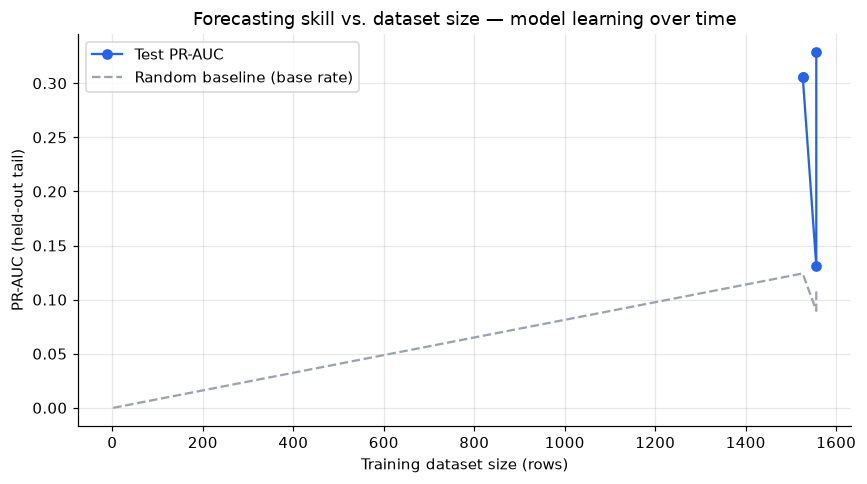

,retrain_date,data_through,n_rows,n_failures,fail_rate,test_PR_AUC,test_ROC_AUC
0,2026-11-08,2026-11-06,2,0,0.0000,NaN,NaN
1,2026-11-08,2026-11-07,1526,129,0.0845,0.3062,0.6760
2,2026-11-08,2026-11-07,1526,129,0.0845,0.3062,0.6760
3,2026-11-09,2026-11-07,1556,130,0.0835,0.1312,0.5844
4,2026-11-10,2026-11-07,1556,130,0.0835,0.3289,0.7324


In [21]:
import matplotlib.pyplot as plt

hist_path = OUT / "performance_history.csv"
if hist_path.is_file():
    H = pd.read_csv(hist_path)
    H = H.sort_values("n_rows").reset_index(drop=True)
    if len(H) >= 1:
        fig, ax1 = plt.subplots(figsize=(8, 4.5))
        ax1.plot(H["n_rows"], H["test_PR_AUC"], "o-", color="#2563eb", label="Test PR-AUC")
        if "base_rate" in H:
            ax1.plot(H["n_rows"], H["base_rate"], "--", color="#9ca3af", label="Random baseline (base rate)")
        ax1.set_xlabel("Training dataset size (rows)")
        ax1.set_ylabel("PR-AUC (held-out tail)")
        ax1.set_title("Forecasting skill vs. dataset size — model learning over time")
        ax1.legend(loc="best"); ax1.grid(alpha=.3)
        fig.tight_layout(); fig.savefig(OUT / "14_performance_over_time.png", dpi=130)
        plt.show()
        display(H[["retrain_date", "data_through", "n_rows", "n_failures",
                   "fail_rate", "test_PR_AUC", "test_ROC_AUC"]])
    else:
        print("performance_history.csv is empty — run the weekly retrain a few times first.")
else:
    print("No performance_history.csv yet. It is created by retrain_weekly.py once the")
    print("weekly retrain job has run. See DEPLOY_PYTHONANYWHERE.md for scheduling.")


## 15. Results summary (for the thesis)

In [19]:
def g(df, name, col="PR-AUC"):
    r = df[df["model"].str.contains(name, regex=False)]
    return float(r[col].iloc[0]) if len(r) else np.nan

summary = pd.DataFrame([
    ["Next-day DQ failure — main model (test PR-AUC)", f"{average_precision_score(yte, p_te):.3f}  vs random {yte.mean():.3f}"],
    ["Main model ROC-AUC (test)", f"{roc_auc_score(yte, p_te):.3f}"],
    ["Selected algorithm / imbalance", f"{BEST_ALGO} / {BEST_IMB}"],
    ["Recall at chosen threshold", f"{op['recall'][0]:.2f}  ({op['false alarms / month'][0]:.1f} false alarms / month)"],
    ["DATA-only vs INFRA-only PR-AUC (N2)", f"{g(baseline_tbl,'ML: DATA only'):.3f} vs {g(baseline_tbl,'ML: INFRA only'):.3f}"],
    ["Best rule baseline PR-AUC", f"{baseline_tbl[baseline_tbl.model.str.startswith('Rule')]['PR-AUC'].max():.3f}"],
    ["Failures warned ≥1 / ≥2 days ahead (N4)", f"{(runup >= 1).mean():.0%} / {(runup >= 2).mean():.0%}"],
    ["Leaky vs honest PR-AUC (N5)", f"{leak_tbl.loc[0,'PR-AUC']:.3f} vs {leak_tbl.loc[1,'PR-AUC']:.3f}"],
], columns=["Result", "Value"])
display(summary); summary.to_csv(OUT / "15_summary.csv", index=False)
print("\nPredictability map (N1):"); display(pmap[[c for c in ["city","failure type","events","lift","verdict"] if c in pmap]].round(2))
print(f"\nAll tables and figures saved in: {OUT.resolve()}")

,Result,Value
0,Next-day DQ failure — main model (test PR-AUC),0.229 vs random 0.111
1,Main model ROC-AUC (test),0.695
2,Selected algorithm / imbalance,RandomForest / none
3,Recall at chosen threshold,0.58 (6.0 false alarms / month)
4,DATA-only vs INFRA-only PR-AUC (N2),0.217 vs 0.116
5,Best rule baseline PR-AUC,0.169
6,Failures warned ≥1 / ≥2 days ahead (N4),58% / 40%
7,Leaky vs honest PR-AUC (N5),1.000 vs 0.229



Predictability map (N1):


,city,failure type,events,lift,verdict
0,Delhi,DATA_QUALITY_FAILURE,130,2.27,PREDICTABLE (lift CI > 1)
1,Delhi,API_SLA_BREACH,3,NaN,too few events to test
2,Pune,DATA_QUALITY_FAILURE,8,1.43,NOT reliably predictable
3,Pune,API_SLA_BREACH,3,NaN,too few events to test



All tables and figures saved in: D:\DPFP_PROJECT\outputs
